In [ ]:
import numpy as np
import matplotlib.pyplot as plt







## Ograniczenia: $\alpha$ $\epsilon$ (1,89), v_0 (1,30)

In [ ]:
v_min = 1
v_max = 30

alpha_min = 1
alpha_max = 89

v0 = np.random.uniform(v_min, v_max, size=100000)
alpha = np.random.uniform(alpha_min, alpha_max, size=100000)

print(v0)

v0_x = np.cos(np.deg2rad(alpha))*v0
v0_y = np.sin(np.deg2rad(alpha))*v0

g = 10

[10.76297268  3.30293278 11.61677994 ... 28.23925591 18.44771238
 17.43726897]


#
# Region R1  x $\epsilon$ (4,10), y = 2 must cross

In [ ]:
y1 = 2
x1_min = 4
x1_max = 10

A = -0.5*g
B = v0_y
C = -y1

delta = B**2 - 4*A*C

indexy = (delta >= 0)

maska_R1 = np.zeros(100000, dtype=bool)

t1_1 = (-B[indexy] + np.sqrt(delta[indexy])) / (2*A)
t1_2 = (-B[indexy] - np.sqrt(delta[indexy])) / (2*A)

x1_R1 = v0_x[indexy] * t1_1
x2_R1 = v0_x[indexy] * t1_2

maska_R1[indexy] = ((x1_R1 >= x1_min) & (x1_R1 <= x1_max)) | ((x2_R1 >= x1_min) & (x2_R1 <= x1_max))


## Region R2 x $\epsilon$ (7,8), y = 3 must not cross

In [ ]:
y2 = 3
x2_min = 7
x2_max = 8

A = -0.5*g
B = v0_y
C = -y2

delta = B**2 - 4*A*C

indexy = (delta >= 0)

maska_R2 = np.zeros(100000, dtype=bool)

t2_1 = (-B[indexy] + np.sqrt(delta[indexy])) / (2*A)
t2_2 = (-B[indexy] - np.sqrt(delta[indexy])) / (2*A)

x1_R2 = v0_x[indexy] * t2_1
x2_R2 = v0_x[indexy] * t2_2

maska_R2[indexy] = ((x1_R2 >= x2_min) & (x1_R2 <= x2_max)) | ((x2_R2 >= x2_min) & (x2_R2 <= x2_max))


## Region 3 x = 3, y $\epsilon$ (3,9) must cross

In [ ]:
x3 = 4
y3_min = 3
y3_max = 10

t3 = x3/v0_x

y_R3 = v0_y*t3 - 0.5*g*t3**2

maska_R3 = (y_R3 >= y3_min) & (y_R3 <= y3_max)

## Region4  x = 4, y $\epsilon$ (5,6) must not cross

In [ ]:


x4 = 3
y4_min = 5
y4_max = 6

t4 = x4/v0_x

y_R4 = v0_y*t4 - 0.5*g*t4**2

maska_R4 = (y_R4 >= y4_min) & (y_R4 <= y4_max)



In [ ]:
final_mask = maska_R1 & ~maska_R2 & maska_R3 & ~maska_R4



final_v0 = v0[final_mask]
final_alpha = alpha[final_mask]

## Wykres dopuszczalnych wartości

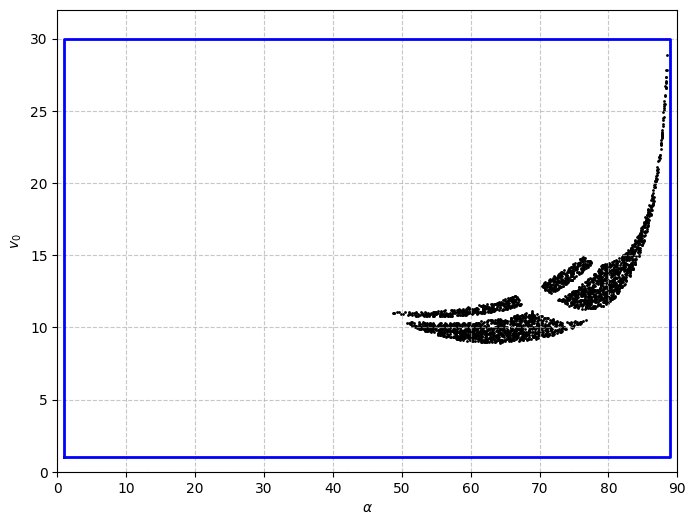

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(final_alpha, final_v0, s=1, c='black', marker='o')

plt.plot([1, 89, 89, 1, 1], [1, 1, 30, 30, 1], color='blue', linewidth=2)

plt.xlabel(r'$\alpha$')
plt.ylabel(r'$v_0$')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0, 90)
plt.ylim(0, 32)

plt.show()

In [ ]:
## Wykres przykładowych trajektorji

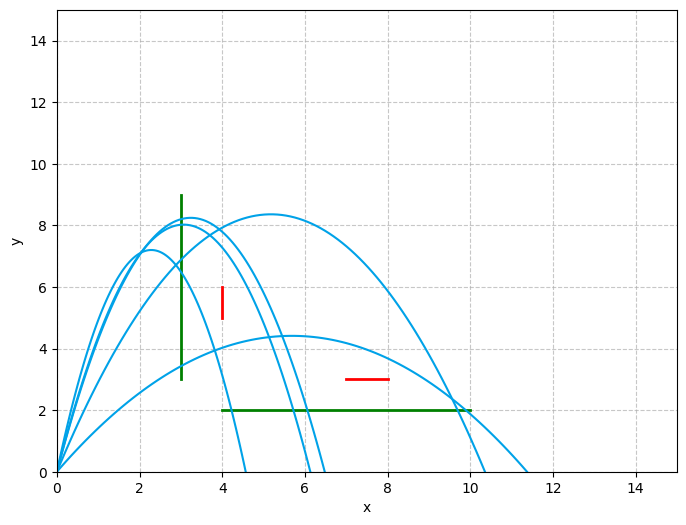

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot([4, 10], [2, 2], color='green', linewidth=2, label='R1 (dozwolony)')

plt.plot([7, 8], [3, 3], color='red', linewidth=2, label='R2 (zabroniony)')

plt.plot([3, 3], [3, 9], color='green', linewidth=2, label='R3 (dozwolony)')

plt.plot([4, 4], [5, 6], color='red', linewidth=2, label='R4 (zabroniony)')

for i in range(5):
    v0_test = final_v0[i]
    alpha_test = final_alpha[i]

    v0x = v0_test * np.cos(np.deg2rad(alpha_test))
    v0y = v0_test * np.sin(np.deg2rad(alpha_test))

    t_koniec = (2 * v0y) / 10
    t = np.linspace(0, t_koniec, 100)

    x = v0x * t
    y = v0y * t - 0.5 * 10 * t**2

    plt.plot(x, y, color='#00A2E8')

plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0, 15)
plt.ylim(0, 15)


plt.show()

###Prawdopodobieństwo spełnienia żądanych warunków


In [ ]:


print(np.size(final_v0)/100000)

0.02772
